2026-10-02 18:58:12.646093: E external/local_xla/xla/stream_executor/cuda/cuda_platform.cc:51] failed call to cuInit: INTERNAL: CUDA error: Failed call to cuInit: UNKNOWN ERROR (303)


INFO:tensorflow:Using MirroredStrategy with devices ('/job:localhost/replica:0/task:0/device:CPU:0',)

Jumlah perangkat GPU yang terdeteksi dan digunakan: 1

🚀 MENJALANKAN SKENARIO_1_S1_SAJA DENGAN ARSITEKTUR BLSTM JEONG
⏳ Melatih model BLSTM Jeong (Fix 100 Epochs, Batch Size 128)...
✅ Evaluasi [Prod]: R2 = 0.7314 | RMSE = 0.9692 t/ha | MAE = 0.5749 | MAPE = 4.17%
✅ Evaluasi [Luas]: R2 = 0.5209 | RMSE = 20.7249 Ha | MAE = 15.6413 | MAPE = 283.38%


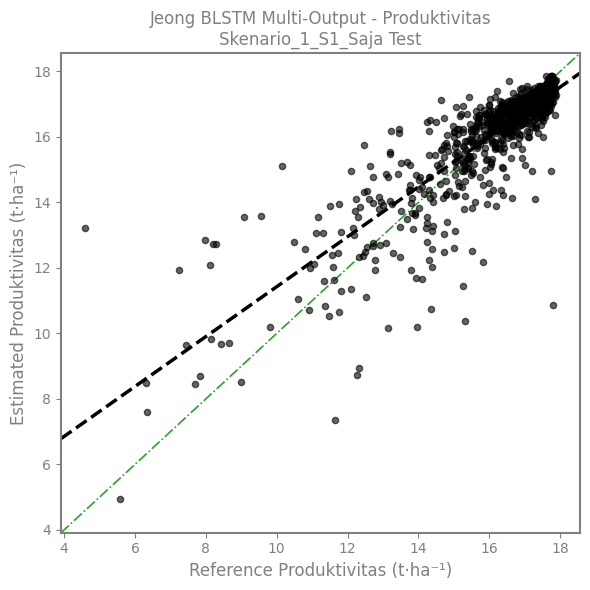

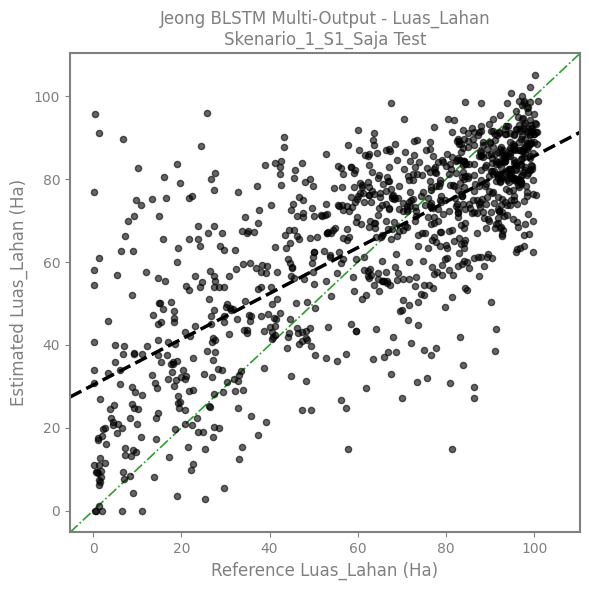

🔮 Memproses prediksi multi-output 2025 untuk 1920 grid...
📁 Data berhasil disimpan ke /kaggle/working/Peta_Prediksi_Multi_Jeong_2025_Skenario_1_S1_Saja.csv



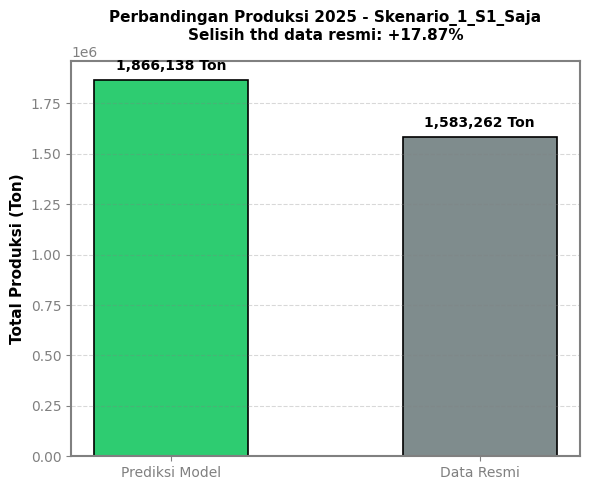


🚀 MENJALANKAN SKENARIO_2_S2_SAJA DENGAN ARSITEKTUR BLSTM JEONG
⏳ Melatih model BLSTM Jeong (Fix 100 Epochs, Batch Size 128)...
✅ Evaluasi [Prod]: R2 = 0.7294 | RMSE = 0.9727 t/ha | MAE = 0.5704 | MAPE = 4.23%
✅ Evaluasi [Luas]: R2 = 0.5413 | RMSE = 20.2791 Ha | MAE = 15.3499 | MAPE = 299.04%


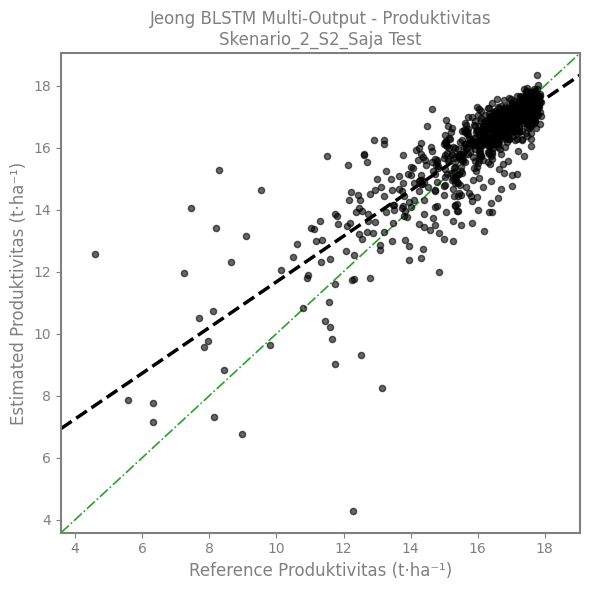

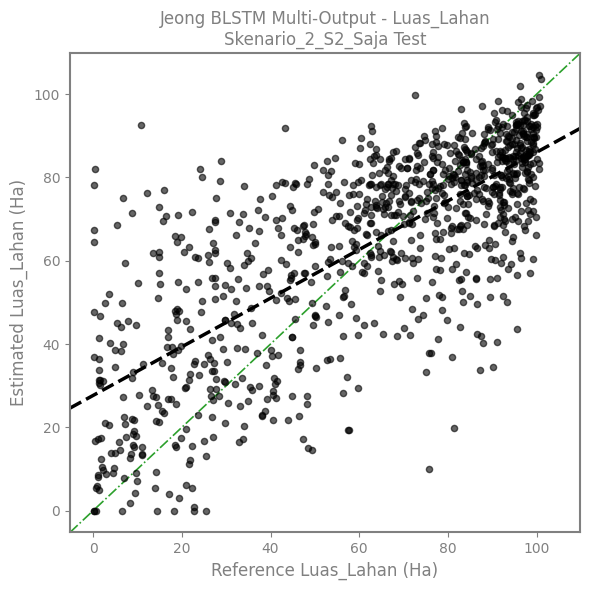

🔮 Memproses prediksi multi-output 2025 untuk 1920 grid...
📁 Data berhasil disimpan ke /kaggle/working/Peta_Prediksi_Multi_Jeong_2025_Skenario_2_S2_Saja.csv



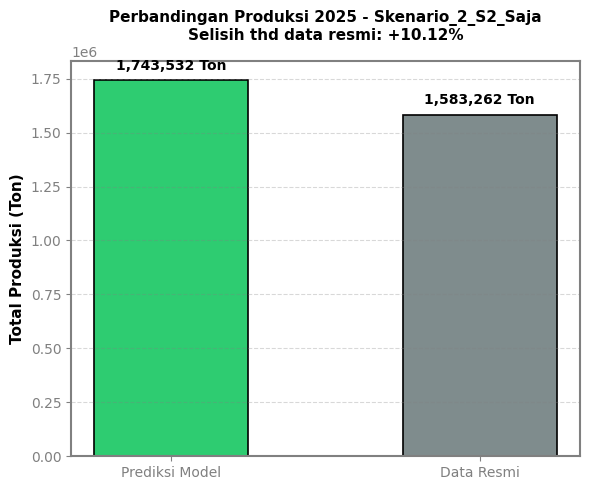


🚀 MENJALANKAN SKENARIO_3_IKLIM_SAJA DENGAN ARSITEKTUR BLSTM JEONG
⏳ Melatih model BLSTM Jeong (Fix 100 Epochs, Batch Size 128)...
✅ Evaluasi [Prod]: R2 = 0.4828 | RMSE = 1.3449 t/ha | MAE = 0.8700 | MAPE = 6.43%
✅ Evaluasi [Luas]: R2 = 0.2723 | RMSE = 25.5425 Ha | MAE = 21.2631 | MAPE = 356.83%


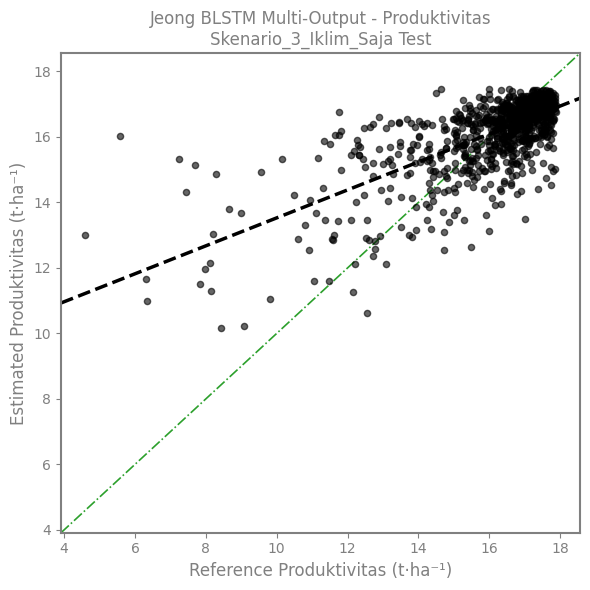

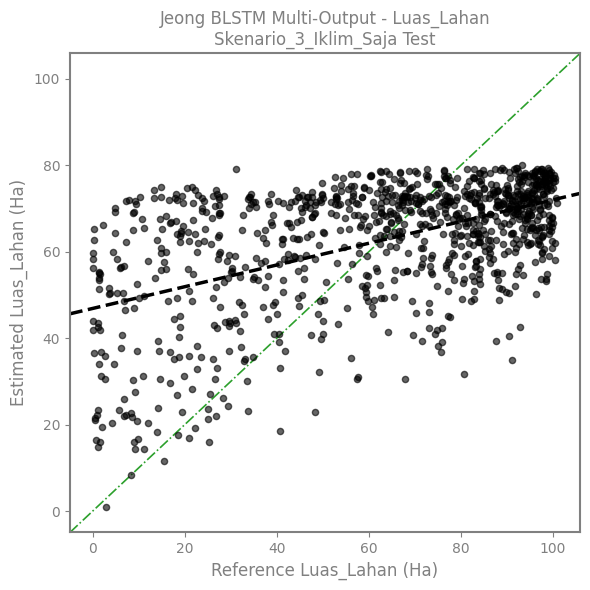

🔮 Memproses prediksi multi-output 2025 untuk 1920 grid...
📁 Data berhasil disimpan ke /kaggle/working/Peta_Prediksi_Multi_Jeong_2025_Skenario_3_Iklim_Saja.csv



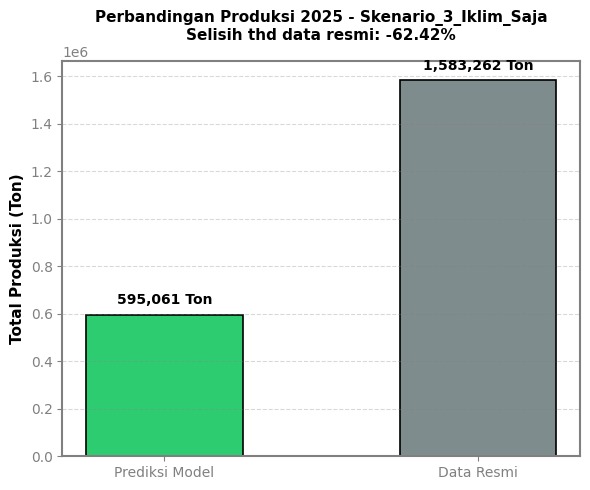


🚀 MENJALANKAN SKENARIO_4_S1_S2 DENGAN ARSITEKTUR BLSTM JEONG
⏳ Melatih model BLSTM Jeong (Fix 100 Epochs, Batch Size 128)...
✅ Evaluasi [Prod]: R2 = 0.8117 | RMSE = 0.8116 t/ha | MAE = 0.4934 | MAPE = 3.57%
✅ Evaluasi [Luas]: R2 = 0.5801 | RMSE = 19.4030 Ha | MAE = 14.5471 | MAPE = 265.07%


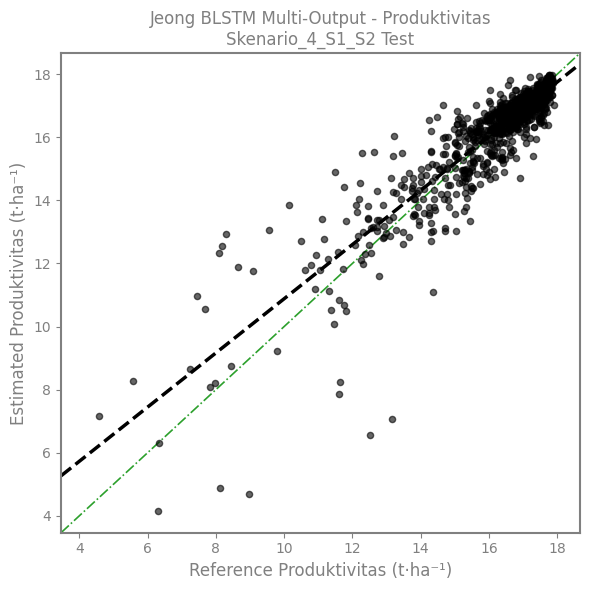

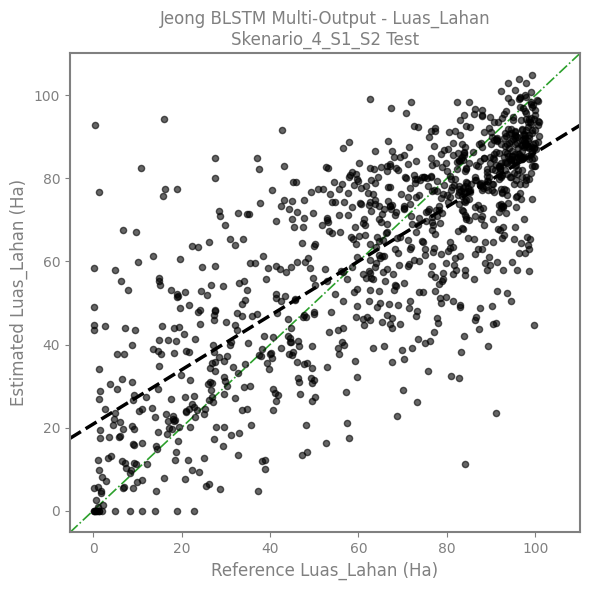

🔮 Memproses prediksi multi-output 2025 untuk 1920 grid...
📁 Data berhasil disimpan ke /kaggle/working/Peta_Prediksi_Multi_Jeong_2025_Skenario_4_S1_S2.csv



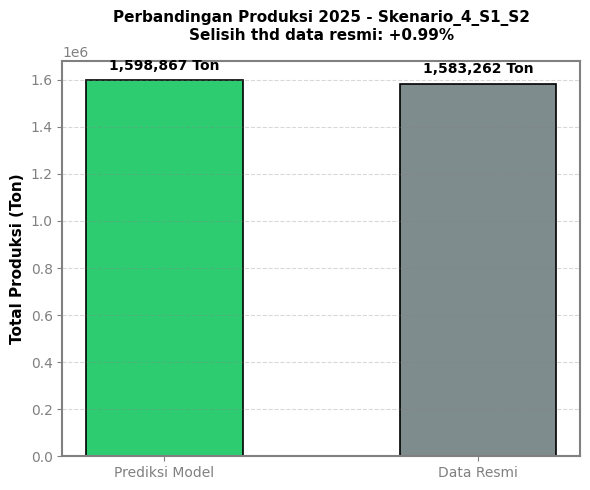


🚀 MENJALANKAN SKENARIO_5_SEMUA_FITUR DENGAN ARSITEKTUR BLSTM JEONG
⏳ Melatih model BLSTM Jeong (Fix 100 Epochs, Batch Size 128)...
✅ Evaluasi [Prod]: R2 = 0.8072 | RMSE = 0.8211 t/ha | MAE = 0.4996 | MAPE = 3.67%
✅ Evaluasi [Luas]: R2 = 0.6089 | RMSE = 18.7240 Ha | MAE = 14.1087 | MAPE = 237.60%


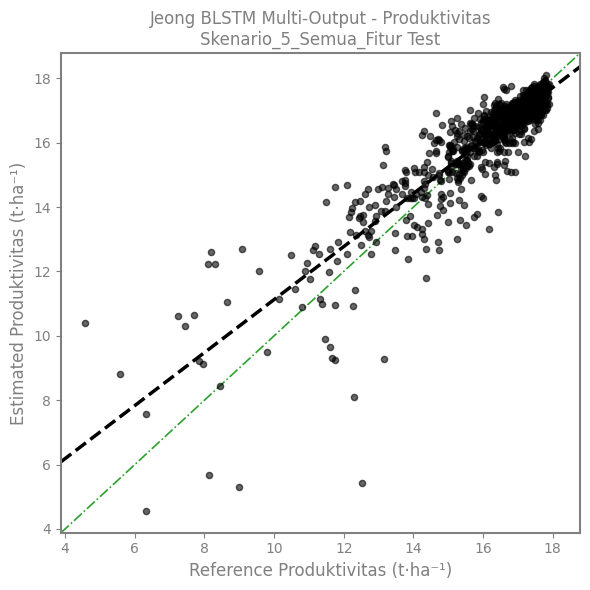

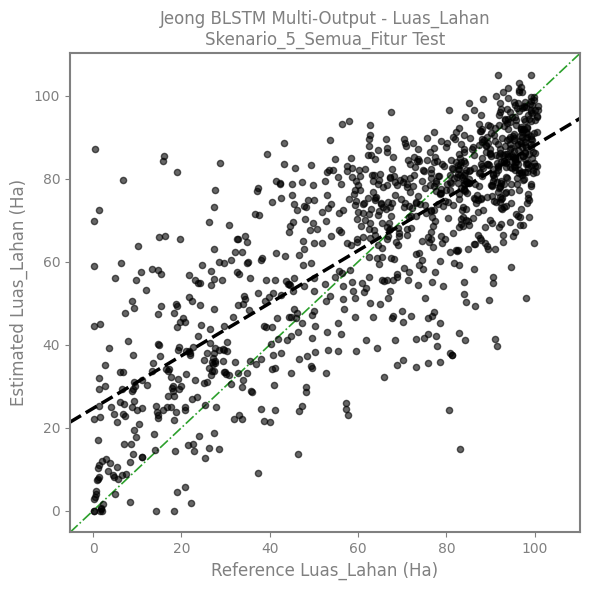

🔮 Memproses prediksi multi-output 2025 untuk 1920 grid...
📁 Data berhasil disimpan ke /kaggle/working/Peta_Prediksi_Multi_Jeong_2025_Skenario_5_Semua_Fitur.csv



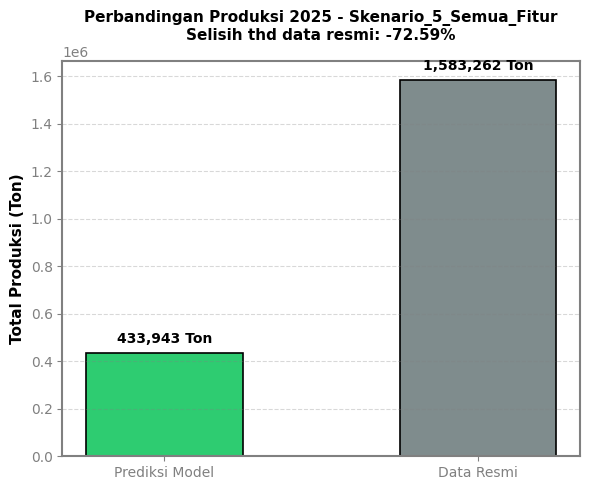


🏆 REKAPITULASI EVALUASI MULTI-OUTPUT BLSTM JEONG:
              Skenario  R2_Prod  RMSE_Prod  MAE_Prod  MAPE_Prod_%  R2_Luas  RMSE_Luas  MAE_Luas  MAPE_Luas_%
    Skenario_1_S1_Saja   0.7314     0.9692    0.5749         4.17   0.5209    20.7249   15.6413       283.38
    Skenario_2_S2_Saja   0.7294     0.9727    0.5704         4.23   0.5413    20.2791   15.3499       299.04
 Skenario_3_Iklim_Saja   0.4828     1.3449    0.8700         6.43   0.2723    25.5425   21.2631       356.83
      Skenario_4_S1_S2   0.8117     0.8116    0.4934         3.57   0.5801    19.4030   14.5471       265.07
Skenario_5_Semua_Fitur   0.8072     0.8211    0.4996         3.67   0.6089    18.7240   14.1087       237.60

📊 REKAPITULASI TOTAL PRODUKSI (PRODUKTIVITAS x LUAS LAHAN DINAMIS) vs DATA RESMI:
              Skenario  Total_Produksi_Prediksi_Ton  Target_Resmi_Ton  Selisih_%
      Skenario_4_S1_S2                 1598867.2500         1583262.0   0.990000
    Skenario_2_S2_Saja                 1743532.000

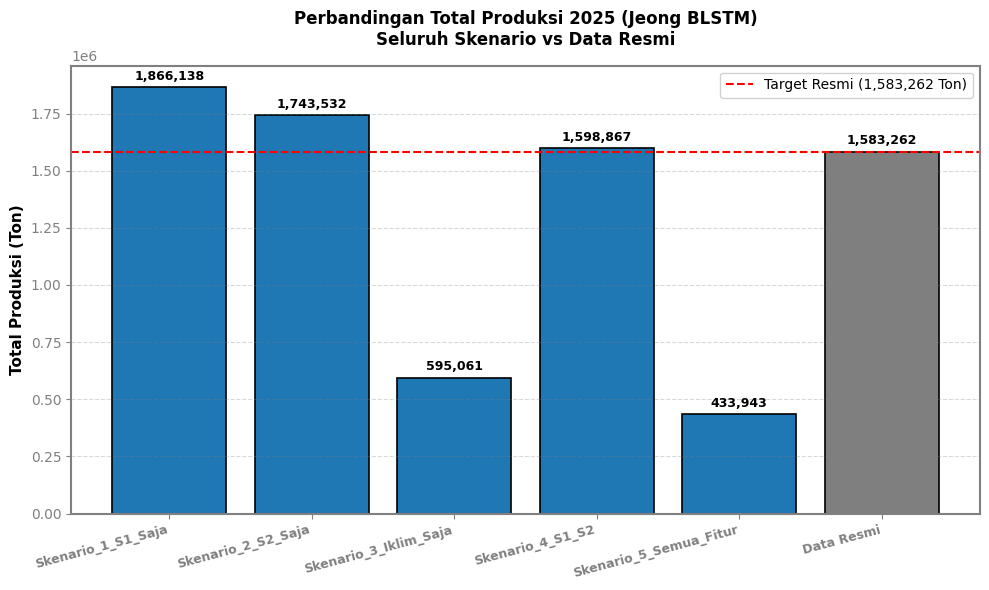

In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import os
import gc
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler
from sklearn.metrics import mean_squared_error, mean_absolute_error, r2_score, mean_absolute_percentage_error
import tensorflow as tf
from tensorflow.keras.models import Model
from tensorflow.keras.layers import Input, LSTM, Dense, Concatenate, Dropout, LeakyReLU, Bidirectional
from tensorflow.keras.optimizers import Adam
import tensorflow.keras.backend as K

# --- PERBAIKAN MEMORI UNTUK KAGGLE (CEGAH QUEUED/DEADLOCK) ---
gpus = tf.config.list_physical_devices('GPU')
if gpus:
    try:
        for gpu in gpus:
            tf.config.experimental.set_memory_growth(gpu, True)
    except RuntimeError as e:
        print(e)

# =====================================================================
# 1. FUNGSI VISUALISASI PROFESIONAL
# =====================================================================
def visualisasi_scatter(y_true, y_pred, title_skenario, nama_target="Produktivitas"):
    plt.figure(figsize=(6, 6))
    plt.scatter(y_true, y_pred, color='black', s=20, alpha=0.6)
    
    min_val = min(y_true.min(), y_pred.min())
    max_val = max(y_true.max(), y_pred.max())
    margin = (max_val - min_val) * 0.05
    ax_min = min_val - margin
    ax_max = max_val + margin
    
    plt.plot([ax_min, ax_max], [ax_min, ax_max], color='#2ca02c', linestyle='-.', linewidth=1.2, zorder=0)
    
    if len(y_true) > 1:
        z = np.polyfit(y_true, y_pred, 1)
        p = np.poly1d(z)
        x_trend = np.linspace(ax_min, ax_max, 100) 
        plt.plot(x_trend, p(x_trend), color='black', linestyle='--', linewidth=2.5, zorder=1)

    satuan = 't·ha⁻¹' if 'Produktivitas' in nama_target else 'Ha'
    plt.xlabel(f'Reference {nama_target} ({satuan})', fontsize=12, color='gray')
    plt.ylabel(f'Estimated {nama_target} ({satuan})', fontsize=12, color='gray')
    plt.xlim(ax_min, ax_max)
    plt.ylim(ax_min, ax_max)
    plt.title(f'Jeong BLSTM Multi-Output - {nama_target}\n{title_skenario}', fontsize=12, color='gray')
    
    ax = plt.gca()
    for spine in ax.spines.values():
        spine.set_edgecolor('gray')
        spine.set_linewidth(1.5)
    ax.tick_params(axis='both', colors='gray', labelsize=10)
    
    plt.tight_layout()
    plt.savefig(f'/kaggle/working/Scatter_Multi_{nama_target}_{title_skenario.replace(" ", "_").replace("+", "plus")}.png', dpi=300)
    plt.show()

def visualisasi_perbandingan_produksi(total_prediksi_ton, target_resmi_ton, nama_skenario):
    fig, ax = plt.subplots(figsize=(6, 5))
    labels = ['Prediksi Model', 'Data Resmi']
    values = [total_prediksi_ton, target_resmi_ton]
    
    colors = ['#2ecc71', '#7f8c8d']
    bars = ax.bar(labels, values, color=colors, edgecolor='black', linewidth=1.2, width=0.5)
    
    for b, v in zip(bars, values):
        ax.text(b.get_x() + b.get_width() / 2, v + (max(values)*0.02), f"{v:,.0f} Ton", 
                ha='center', va='bottom', fontsize=10, fontweight='bold', color='black')
        
    selisih_persen = (total_prediksi_ton - target_resmi_ton) / target_resmi_ton * 100
    ax.set_ylabel('Total Produksi (Ton)', fontsize=11, fontweight='bold', color='black')
    ax.set_title(f'Perbandingan Produksi 2025 - {nama_skenario}\nSelisih thd data resmi: {selisih_persen:+.2f}%', 
                 fontsize=11, fontweight='bold', color='black', pad=15)
    
    for spine in ax.spines.values():
        spine.set_linewidth(1.5)
        spine.set_color('gray')
    ax.tick_params(axis='both', colors='gray', labelsize=10)
    ax.grid(axis='y', linestyle='--', alpha=0.3, color='gray')
    
    plt.tight_layout()
    plt.savefig(f'/kaggle/working/Perbandingan_Produksi_{nama_skenario.replace(" ", "_")}.png', dpi=300)
    plt.show()

def visualisasi_semua_skenario_produksi(hasil_produksi_list, target_resmi_ton):
    if not hasil_produksi_list:
        return
    
    df_plot = pd.DataFrame(hasil_produksi_list)
    
    fig, ax = plt.subplots(figsize=(10, 6))
    labels = df_plot['Skenario'].tolist() + ['Data Resmi']
    values = df_plot['Total_Produksi_Prediksi_Ton'].tolist() + [target_resmi_ton]
    
    colors = ['#1f77b4'] * len(df_plot) + ['#7f7f7f']
    bars = ax.bar(labels, values, color=colors, edgecolor='black', linewidth=1.2)
    
    for b, v in zip(bars, values):
        ax.text(b.get_x() + b.get_width() / 2, v + (max(values)*0.01), f"{v:,.0f}", ha='center', va='bottom', fontsize=9, fontweight='bold')
        
    ax.set_ylabel('Total Produksi (Ton)', fontsize=11, fontweight='bold', color='black')
    ax.set_title('Perbandingan Total Produksi 2025 (Jeong BLSTM)\nSeluruh Skenario vs Data Resmi', fontsize=12, fontweight='bold', pad=15)
    
    ax.axhline(target_resmi_ton, color='red', linestyle='--', linewidth=1.5, label=f'Target Resmi ({target_resmi_ton:,.0f} Ton)')
    ax.legend(loc='upper right', frameon=True, facecolor='white', framealpha=0.9)
    
    for spine in ax.spines.values():
        spine.set_linewidth(1.5)
        spine.set_color('gray')
    ax.tick_params(axis='both', colors='gray', labelsize=10)
    ax.grid(axis='y', linestyle='--', alpha=0.3, color='gray')
    
    plt.xticks(rotation=15, ha='right', fontsize=9, fontweight='bold')
    plt.tight_layout()
    plt.savefig('/kaggle/working/Perbandingan_Semua_Skenario_Produksi_Jeong.png', dpi=300)
    plt.show()

# =====================================================================
# 2. FUNGSI PENGAMAN MULTI-GPU (MULTI-OUTPUT PADDING)
# =====================================================================
def padding_multi_gpu_multi(X_g, X_c, y_prod=None, y_luas=None, batch_size=64):
    n_samples = len(X_g)
    if n_samples == 0:
        return X_g, X_c, y_prod, y_luas, 0

    sisa = n_samples % batch_size
    if sisa != 0:
        pad_len = batch_size - sisa
        idx_pad = np.resize(np.arange(n_samples), pad_len)

        X_g = np.concatenate([X_g, X_g[idx_pad]], axis=0)
        X_c = np.concatenate([X_c, X_c[idx_pad]], axis=0)
        if y_prod is not None:
            y_prod = np.concatenate([y_prod, y_prod[idx_pad]], axis=0)
        if y_luas is not None:
            y_luas = np.concatenate([y_luas, y_luas[idx_pad]], axis=0)

    return X_g, X_c, y_prod, y_luas, n_samples

# =====================================================================
# 3. PERSIAPAN DATA DAN SKENARIO FITUR
# =====================================================================
PATH_2224 = "/kaggle/input/datasets/jejehayu/dataset-regresi-padi/Dataset_Siap_Modeling_Padi_P3_Fixed.csv"
PATH_2025 = "/kaggle/input/datasets/jejehayu/dataset-regresi-2025/Dataset_Regresi_2025 (1).csv"
TARGET_PRODUKSI_RESMI_2025_TON = 1_583_262.0

if not os.path.exists(PATH_2224):
    PATH_2224 = "Dataset_Siap_Modeling_Padi_P3_Fixed.csv"
if not os.path.exists(PATH_2025):
    PATH_2025 = "Dataset_Regresi_2025.csv"

df_2224 = pd.read_csv(PATH_2224)
df_2025 = pd.read_csv(PATH_2025)

def bersihkan_df(df_temp):
    if 'Grid_ID' in df_temp.columns:
        df_temp.rename(columns={'Grid_ID': 'ID_Grid'}, inplace=True)
        
    # --- LOGIKA PENANGANAN CURAH HUJAN (x dan y) ---
    if 'Curah_Hujan_y' in df_temp.columns:
        df_temp.rename(columns={'Curah_Hujan_y': 'Curah_Hujan'}, inplace=True)
        # Jika ada Curah_Hujan_x (dari ERA5), kita buang saja agar tidak double
        if 'Curah_Hujan_x' in df_temp.columns:
            df_temp.drop(columns=['Curah_Hujan_x'], inplace=True)
    elif 'Curah_Hujan_P3' in df_temp.columns:
        df_temp.rename(columns={'Curah_Hujan_P3': 'Curah_Hujan'}, inplace=True)
    # -----------------------------------------------

    if 'tahun_bulan' in df_temp.columns:
        df_temp.rename(columns={'tahun_bulan': 'Tahun_Bulan'}, inplace=True)

    if 'Tahun_Bulan' in df_temp.columns and 'Tahun' not in df_temp.columns:
        df_temp['Tahun_Bulan'] = df_temp['Tahun_Bulan'].astype(str)
        df_temp['Tahun'] = df_temp['Tahun_Bulan'].str[:4].astype(int)
        df_temp['Bulan'] = df_temp['Tahun_Bulan'].str[-2:].astype(int)

    return df_temp.sort_values(by=['ID_Grid', 'Tahun', 'Bulan']).reset_index(drop=True)

df_2224 = bersihkan_df(df_2224)
df_2025 = bersihkan_df(df_2025)

fitur_s1 = ['VV_median', 'VH_median', 'RVI_median', 'NDPI_median', 'CrossRatio_median']
fitur_s2 = ['NDVI_median', 'EVI_median', 'LSWI_median', 'GNDVI_median', 'S2REP_median', 'BSI_median']
fitur_iklim = ['Suhu_2m', 'Kelembapan_Tanah', 'Radiasi_Matahari', 'Curah_Hujan']

fitur_s1 = [f for f in fitur_s1 if f in df_2224.columns]
fitur_s2 = [f for f in fitur_s2 if f in df_2224.columns]
fitur_iklim = [f for f in fitur_iklim if f in df_2224.columns]

skenario_dict = {
    "Skenario_1_S1_Saja": fitur_s1,
    "Skenario_2_S2_Saja": fitur_s2,
    "Skenario_3_Iklim_Saja": fitur_iklim,
    "Skenario_4_S1_S2": fitur_s1 + fitur_s2,
    "Skenario_5_Semua_Fitur": fitur_s1 + fitur_s2 + fitur_iklim
}

def ekstraksi_sekuens_multi(df_source, daftar_fitur, has_target=True):
    gData_list, coord_list, y_prod_list, y_luas_list, grid_ids = [], [], [], [], []
    expected_steps = df_source.groupby(['ID_Grid', 'Tahun']).size().max()

    for (id_grid, tahun), group in df_source.groupby(['ID_Grid', 'Tahun']):
        if len(group) == expected_steps:
            if has_target:
                if 'Target_Produksi_Grid_Ton' in group.columns and 'Luas_Padi_Ha' in group.columns:
                    total_target = group['Target_Produksi_Grid_Ton'].sum(skipna=True)
                    luas_padi = group['Luas_Padi_Ha'].max()
                    if total_target > 0 and luas_padi > 0:
                        yield_ha = total_target / luas_padi
                        gData_list.append(group[daftar_fitur].values)
                        coord_list.append(group[['Latitude', 'Longitude']].iloc[0].values)
                        y_prod_list.append(yield_ha)
                        y_luas_list.append(luas_padi)
                        grid_ids.append(id_grid)
            else:
                gData_list.append(group[daftar_fitur].values)
                coord_list.append(group[['Latitude', 'Longitude']].iloc[0].values)
                grid_ids.append(id_grid)

    if has_target:
        return np.array(gData_list), np.array(coord_list), np.array(y_prod_list), np.array(y_luas_list), expected_steps, grid_ids
    else:
        return np.array(gData_list), np.array(coord_list), None, None, expected_steps, grid_ids

hasil_evaluasi = []
hasil_produksi = []

# =====================================================================
# 4. INISIALISASI STRATEGI MULTI-GPU (MIRRORED STRATEGY)
# =====================================================================
K.clear_session()
gc.collect()

strategy = tf.distribute.MirroredStrategy()
print(f'\nJumlah perangkat GPU yang terdeteksi dan digunakan: {strategy.num_replicas_in_sync}')

# Batch size dikunci di 128 mengikuti paper Jeong (dibagi ke n-GPU)
GLOBAL_BATCH_SIZE = 128

# =====================================================================
# 5. LOOPING EKSEKUSI (BLSTM JEONG MURNI -> MULTI-OUTPUT)
# =====================================================================
for nama_skenario, daftar_fitur in skenario_dict.items():
    if len(daftar_fitur) == 0:
        continue

    print(f"\n{'='*75}")
    print(f"🚀 MENJALANKAN {nama_skenario.upper()} DENGAN ARSITEKTUR BLSTM JEONG")

    K.clear_session()
    gc.collect()
    tf.compat.v1.reset_default_graph()

    # --- A. Ekstraksi Data Multi-Output ---
    gData_2224, coord_2224, y_prod_2224, y_luas_2224, steps_2224, _ = ekstraksi_sekuens_multi(df_2224, daftar_fitur, has_target=True)
    gData_25, coord_25, _, _, steps_25, grids_25 = ekstraksi_sekuens_multi(df_2025, daftar_fitur, has_target=False)

    time_steps = steps_2224
    num_features = len(daftar_fitur)

    if len(gData_2224) == 0:
        print(f"⚠️ Melewati skenario karena jumlah data valid 0.")
        continue

    # --- B. Pemisahan Data (Train 80%, Test 20%) ---
    X_train_g, X_test_g, y_train_p, y_test_p = train_test_split(gData_2224, y_prod_2224, test_size=0.20, random_state=42)
    X_train_c, X_test_c, y_train_l, y_test_l = train_test_split(coord_2224, y_luas_2224, test_size=0.20, random_state=42)

    X_pred_g = gData_25
    X_pred_c = coord_25

    # --- C. Standardisasi Fitur & Dual Target ---
    scaler_g = StandardScaler()
    X_train_g = scaler_g.fit_transform(X_train_g.reshape(-1, num_features)).reshape(X_train_g.shape)
    X_test_g = scaler_g.transform(X_test_g.reshape(-1, num_features)).reshape(X_test_g.shape)

    scaler_c = StandardScaler()
    X_train_c = scaler_c.fit_transform(X_train_c)
    X_test_c = scaler_c.transform(X_test_c)

    scaler_y_prod = StandardScaler()
    y_train_p_scaled = scaler_y_prod.fit_transform(y_train_p.reshape(-1, 1))
    y_test_p_scaled = scaler_y_prod.transform(y_test_p.reshape(-1, 1))

    scaler_y_luas = StandardScaler()
    y_train_l_scaled = scaler_y_luas.fit_transform(y_train_l.reshape(-1, 1))
    y_test_l_scaled = scaler_y_luas.transform(y_test_l.reshape(-1, 1))

    # --- D. PADDING MULTI-GPU ---
    X_train_g_pad, X_train_c_pad, y_train_p_pad, y_train_l_pad, _ = padding_multi_gpu_multi(
        X_train_g, X_train_c, y_train_p_scaled, y_train_l_scaled, GLOBAL_BATCH_SIZE
    )
    X_test_g_pad, X_test_c_pad, y_test_p_pad, y_test_l_pad, orig_test_len = padding_multi_gpu_multi(
        X_test_g, X_test_c, y_test_p_scaled, y_test_l_scaled, GLOBAL_BATCH_SIZE
    )

    # --- E. ARSITEKTUR BLSTM JEONG (DISESUAIKAN UNTUK MULTI-OUTPUT) ---
    with strategy.scope():
        # Input Layer
        input_g = Input(shape=(time_steps, num_features), name="Input_Sekuensial")
        
        # BLSTM Layer (64 Neurons)
        bilstm_layer = Bidirectional(LSTM(units=64, return_sequences=False))(input_g)

        # Spatial Coordinates Gabungan
        input_coord = Input(shape=(2,), name="Input_Koordinat")
        merged = Concatenate()([bilstm_layer, input_coord])

        # Dense Layer 1 (64 Neurons, LeakyReLU, Dropout 0.3)
        x = Dense(64)(merged)
        x = LeakyReLU()(x)
        x = Dropout(0.3)(x)

        # Dense Layer 2 (64 Neurons, LeakyReLU, Dropout 0.3)
        x = Dense(64)(x)
        x = LeakyReLU()(x)
        x = Dropout(0.3)(x)

        # Multi-Output Branches
        output_produktivitas = Dense(1, activation='linear', name="output_produktivitas")(x)
        output_luas_lahan = Dense(1, activation='linear', name="output_luas_lahan")(x)

        model = Model(
            inputs=[input_g, input_coord], 
            outputs=[output_produktivitas, output_luas_lahan]
        )
        
        # Optimizer Adam (LR 0.001)
        model.compile(
            optimizer=Adam(learning_rate=0.001),
            loss='mse', # Menggunakan MSE sesuai paper regresi standar
            metrics={
                'output_produktivitas': ['mae'],
                'output_luas_lahan': ['mae']
            }
        )

    # --- F. Pelatihan Model (Fix 100 Epochs sesuai Tabel Jeong) ---
    print(f"⏳ Melatih model BLSTM Jeong (Fix 100 Epochs, Batch Size 128)...")
    model.fit(
        [X_train_g_pad, X_train_c_pad], 
        [y_train_p_pad, y_train_l_pad],
        validation_data=([X_test_g_pad, X_test_c_pad], [y_test_p_pad, y_test_l_pad]),
        epochs=100, 
        batch_size=GLOBAL_BATCH_SIZE,
        verbose=0
    )

    # --- G. Evaluasi Model ---
    preds_test = model.predict([X_test_g_pad, X_test_c_pad], batch_size=GLOBAL_BATCH_SIZE, verbose=0)
    
    y_pred_p_scaled = preds_test[0][:orig_test_len]
    y_pred_p_act = scaler_y_prod.inverse_transform(y_pred_p_scaled).flatten()

    y_pred_l_scaled = preds_test[1][:orig_test_len]
    y_pred_l_act = scaler_y_luas.inverse_transform(y_pred_l_scaled).flatten()

    # Hitung error Produktivitas
    r2_p = r2_score(y_test_p, y_pred_p_act)
    rmse_p = np.sqrt(mean_squared_error(y_test_p, y_pred_p_act))
    mae_p = mean_absolute_error(y_test_p, y_pred_p_act)
    mape_p = mean_absolute_percentage_error(y_test_p, y_pred_p_act) * 100
    
    # Hitung error Luas Lahan
    r2_l = r2_score(y_test_l, y_pred_l_act)
    rmse_l = np.sqrt(mean_squared_error(y_test_l, y_pred_l_act))
    mae_l = mean_absolute_error(y_test_l, y_pred_l_act)
    mape_l = mean_absolute_percentage_error(y_test_l, y_pred_l_act) * 100

    hasil_evaluasi.append({
        'Skenario': nama_skenario,
        'R2_Prod': round(r2_p, 4),
        'RMSE_Prod': round(rmse_p, 4),
        'MAE_Prod': round(mae_p, 4),
        'MAPE_Prod_%': round(mape_p, 2),
        'R2_Luas': round(r2_l, 4),
        'RMSE_Luas': round(rmse_l, 4),
        'MAE_Luas': round(mae_l, 4),
        'MAPE_Luas_%': round(mape_l, 2)
    })

    print(f"✅ Evaluasi [Prod]: R2 = {r2_p:.4f} | RMSE = {rmse_p:.4f} t/ha | MAE = {mae_p:.4f} | MAPE = {mape_p:.2f}%")
    print(f"✅ Evaluasi [Luas]: R2 = {r2_l:.4f} | RMSE = {rmse_l:.4f} Ha | MAE = {mae_l:.4f} | MAPE = {mape_l:.2f}%")
    
    visualisasi_scatter(y_test_p, np.maximum(0, y_pred_p_act), f"{nama_skenario} Test", "Produktivitas")
    visualisasi_scatter(y_test_l, np.maximum(0, y_pred_l_act), f"{nama_skenario} Test", "Luas_Lahan")

    # --- H. Prediksi Dinamis Tahun 2025 ---
    if len(X_pred_g) > 0:
        print(f"🔮 Memproses prediksi multi-output 2025 untuk {len(X_pred_g)} grid...")

        X_pred_g_scaled = scaler_g.transform(X_pred_g.reshape(-1, num_features)).reshape(X_pred_g.shape)
        X_pred_c_scaled = scaler_c.transform(X_pred_c)

        X_p_pad, X_c_pad, _, _, orig_p = padding_multi_gpu_multi(X_pred_g_scaled, X_pred_c_scaled, None, None, GLOBAL_BATCH_SIZE)

        preds_2025 = model.predict([X_p_pad, X_c_pad], batch_size=GLOBAL_BATCH_SIZE, verbose=0)
        
        y_pred_2025_prod = scaler_y_prod.inverse_transform(preds_2025[0][:orig_p]).flatten()
        y_pred_2025_luas = scaler_y_luas.inverse_transform(preds_2025[1][:orig_p]).flatten()

        # Zero-bounding
        y_pred_2025_prod = np.maximum(0, y_pred_2025_prod)
        y_pred_2025_luas = np.maximum(0, y_pred_2025_luas)

        df_hasil_pred = pd.DataFrame({
            'ID_Grid': grids_25,
            'Tahun': 2025,
            'Estimasi_Produktivitas_Ton_Ha': y_pred_2025_prod,
            'Estimasi_Luas_Padi_Ha': y_pred_2025_luas
        })

        df_hasil_pred['Estimasi_Produksi_Ton'] = (
            df_hasil_pred['Estimasi_Produktivitas_Ton_Ha'] * df_hasil_pred['Estimasi_Luas_Padi_Ha']
        )

        agg_dict = {'Latitude': 'first', 'Longitude': 'first'}
        exclude_cols = ['ID_Grid', 'Tahun', 'Bulan', 'Tahun_Bulan', 'Latitude', 'Longitude', 'Kecamatan', 'Desa']
        feature_cols = [c for c in df_2025.columns if c not in exclude_cols and pd.api.types.is_numeric_dtype(df_2025[c])]

        for c in feature_cols:
            agg_dict[c] = 'mean'

        df_2025_ringkas = df_2025.groupby(['ID_Grid', 'Tahun'], as_index=False).agg(agg_dict)
        df_peta_2025 = pd.merge(df_2025_ringkas, df_hasil_pred, on=['ID_Grid', 'Tahun'], how='inner')

        nama_file_prediksi = f"/kaggle/working/Peta_Prediksi_Multi_Jeong_2025_{nama_skenario}.csv"
        df_peta_2025.to_csv(nama_file_prediksi, index=False)
        print(f"📁 Data berhasil disimpan ke {nama_file_prediksi}\n")

        total_produksi_ton = df_peta_2025['Estimasi_Produksi_Ton'].sum(skipna=True)
        selisih_ton = total_produksi_ton - TARGET_PRODUKSI_RESMI_2025_TON
        selisih_persen = selisih_ton / TARGET_PRODUKSI_RESMI_2025_TON * 100

        hasil_produksi.append({
            'Skenario': nama_skenario,
            'Total_Produksi_Prediksi_Ton': round(total_produksi_ton, 2),
            'Target_Resmi_Ton': TARGET_PRODUKSI_RESMI_2025_TON,
            'Selisih_%': round(selisih_persen, 2)
        })

        visualisasi_perbandingan_produksi(total_produksi_ton, TARGET_PRODUKSI_RESMI_2025_TON, nama_skenario)

# =====================================================================
# 6. REKAPITULASI AKHIR & VISUALISASI GABUNGAN
# =====================================================================
print("\n" + "="*85)
print("🏆 REKAPITULASI EVALUASI MULTI-OUTPUT BLSTM JEONG:")
print("="*85)
if len(hasil_evaluasi) > 0:
    print(pd.DataFrame(hasil_evaluasi).to_string(index=False))

print("\n" + "="*85)
print("📊 REKAPITULASI TOTAL PRODUKSI (PRODUKTIVITAS x LUAS LAHAN DINAMIS) vs DATA RESMI:")
print("="*85)
if len(hasil_produksi) > 0:
    df_prod = pd.DataFrame(hasil_produksi).sort_values(by='Selisih_%', key=lambda s: s.abs())
    print(df_prod.to_string(index=False))
    
    visualisasi_semua_skenario_produksi(hasil_produksi, TARGET_PRODUKSI_RESMI_2025_TON)